# W08A B · t·F·예측

2026-10-19 · 실제5주차 W05A/W05B 복습. 설명용 실제자료와 각 연습문항의 합성자료를 구별합니다.
한 행은 직원 한 명이 아니라 부서 한 곳입니다. 원래 값은 긍정 응답 비율(%), 값의 변화는 %p입니다.
이번 표기는 p=설명변수 수, k=p+1=절편 포함 계수 수, q=제약 수입니다.

A: `rating ~ complaints + privileges`; B: `rating ~ complaints + learning`; F: `rating ~ .`(나머지 여섯 변수).
수업의 주 모형은 B입니다. A와 B는 서로 중첩되지 않으며, 둘 중 하나와 F의 비교는 별도로 구별합니다.

[함수 목적·입출력·정의 바로가기](https://github.com/lunalab-ai/regre/blob/2026-fall-w08a/src/w08a-review-api.md)

먼저 코드의 결과를 예상하고 실행 후 이유를 적으세요. 연습의 빈칸·의도 오류는 문제문에 있으며 실행 셀은 TODO입니다.
기본 전체 실행 성공은 문제풀이 완료를 뜻하지 않습니다. 온라인R·R Colab·로컬R 중 한 환경을 선택하면 됩니다.
별도 성적 과제·제출기한은 없습니다. R/QMD를 다운로드하면 data폴더를 함께 보관하세요.

CPU R런타임에서 이 노트북만 단독 실행할 수 있습니다. 준비 셀은 검증된 고정 버전의 공통 함수를 받고, 다시 실행할 때 다운로드한 파일의 무결성을 확인합니다.


In [ ]:
helper_ref <- "ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541"
locations <- c("labs/student/w08a/data","../../labs/student/w08a/data")
found <- locations[file.exists(file.path(locations,"mlr-inference.R"))]
data_dir <- if(length(found)) found[1] else file.path(path.expand("~"),".cache","regre",helper_ref)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
options(timeout=120)
target <- file.path(data_dir,"mlr-inference.R")
if(!file.exists(target)) {
  download.file("https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/src/mlr-inference.R",target,mode="wb")
  cat("Downloaded fixed helper: mlr-inference.R\n")
} else cat("Reusing helper cache; checking bytes: mlr-inference.R\n")
if(unname(tools::md5sum(target))!="220bb19be470b1d35e13f48ed562ab96") stop("Helper checksum mismatch; inspect the named file before restarting.")
source(target)
target <- file.path(data_dir,"mlr-tools.R")
if(!file.exists(target)) {
  download.file("https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/src/mlr-tools.R",target,mode="wb")
  cat("Downloaded fixed helper: mlr-tools.R\n")
} else cat("Reusing helper cache; checking bytes: mlr-tools.R\n")
if(unname(tools::md5sum(target))!="7cbdffbadc83fa5e4fe5addf82d9add3") stop("Helper checksum mismatch; inspect the named file before restarting.")
source(target)
cat(R.version.string,"\n")
demo_d <- datasets::attitude
demo_fit_A <- lm(rating ~ complaints+privileges, data=demo_d)
demo_fit_B <- lm(rating ~ complaints+learning, data=demo_d)
demo_fit_F <- lm(rating ~ ., data=demo_d)
demo_models <- list(A=demo_fit_A,B=demo_fit_B,F=demo_fit_F)
demo_scaling <- mlr_scaling(demo_d)
demo_new <- data.frame(complaints=mean(demo_d$complaints),learning=mean(demo_d$learning))
demo_intervals <- mlr_interval_comparison(demo_fit_B,demo_new)
cat("Data: attitude, same 30 complete department rows; original levels in percent.
")
print(data.frame(model=names(demo_models), formula=vapply(demo_models,function(m) paste(deparse(formula(m)),collapse=" "),character(1)), n=30,
                 p=vapply(demo_models,function(m) length(coef(m))-1L,integer(1)),
                 k=vapply(demo_models,function(m) length(coef(m)),integer(1))))


## 설명 예제 · 실제30부서

모형식·행·단위를 먼저 읽고 표의 의미를 설명합니다. 연습문항의 합성 숫자와 구별합니다.

In [ ]:
cat("Partial test: B nested in F; same response and rows
")
print(mlr_nested_f(demo_fit_B,demo_fit_F))
cat("Coefficient inference belongs to model B
")
print(mlr_coefficient_table(demo_fit_B))
cat("Prediction model: B; new condition at training means
")
print(demo_new)
print(demo_intervals)
plot(1:2,demo_intervals$fit,ylim=range(c(demo_intervals$lower,demo_intervals$upper)),
     xaxt="n",pch=19,col="#087f8c",xlab="Prediction target",ylab="Rating (%)")
axis(1,1:2,c("Mean CI","New department PI"))
segments(1:2,demo_intervals$lower,1:2,demo_intervals$upper,lwd=4,col=c("#087f8c","#c35c2a"))


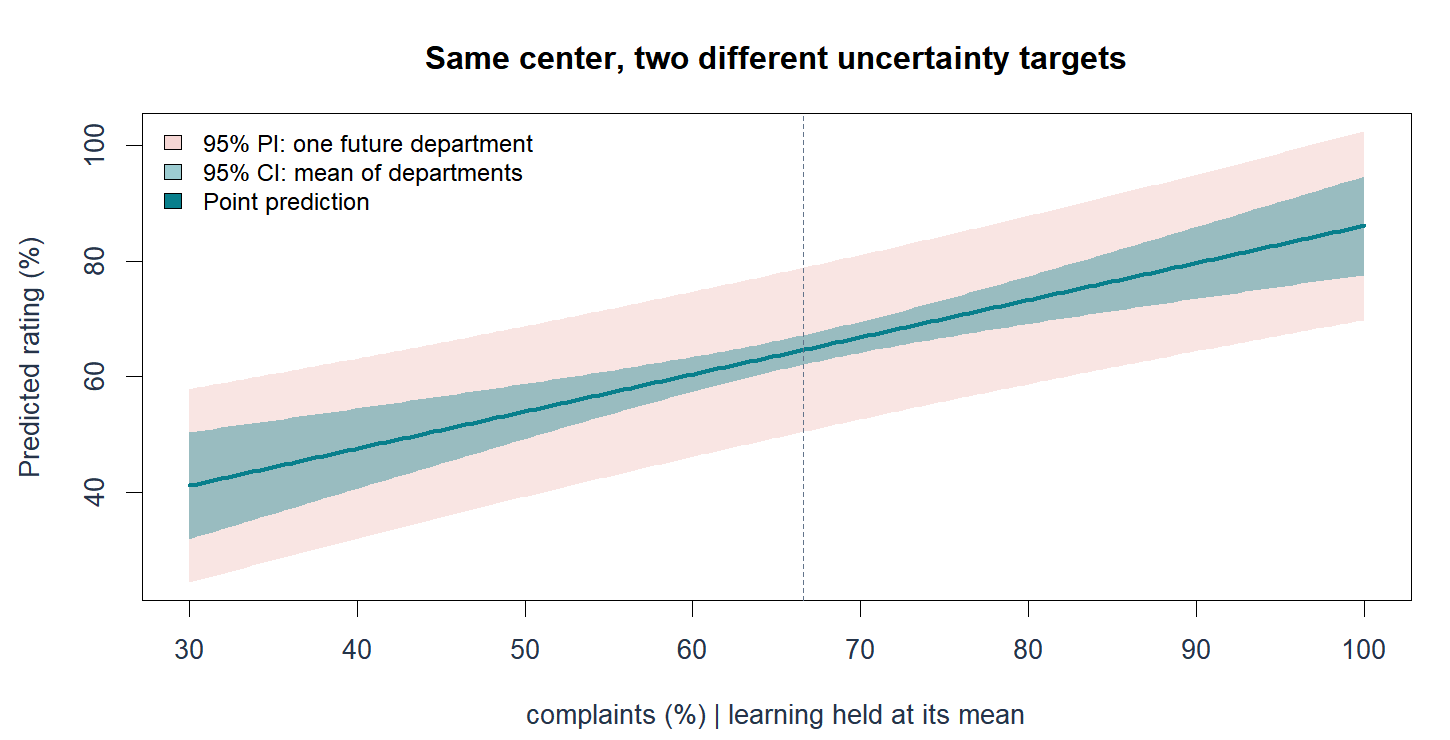

기존 수업의 설명 그림이며 연습문항 답안표가 아닙니다. [원본 PNG](https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/course/notion/w05b/assets/b04-intervals.png) · [원본 위치](https://github.com/lunalab-ai/regre/blob/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/course/notion/w05b/assets/b04-intervals.png)

## Q53 · 귀무값과 계수 신뢰구간

어떤 다중회귀 계수의 추정값은0.8, SE는0.2이다. 귀무가설은 $H_0:\beta=0.2$이며, 해당 자유도·신뢰수준의 양측 임계값은 이 문제에서2.0으로 제공한다. `c`는 두 끝점을 묶는다.

t 통계량의 빈칸을 채우고 t와 계수 신뢰구간을 구하시오. 주어진 양측 기준에서 귀무값0.2가 구간 안에 있는지도 설명하시오.

```r
estimate <- 0.8
null <- 0.2
SE <- 0.2
critical <- 2.0
t_value <- (estimate - ____) / SE
CI <- estimate + c(-1, 1)*critical*SE
print(t_value)
print(CI)
```

In [ ]:
# Q53 TODO: 직접 완성하고 실행하세요.

## Q54 · 전체 F의 분자 자유도

같은24개 관측에 절편과 설명변수 세 개를 넣은 완전계수 OLS 모형이다. $SST=500$, $SSE=200$이며 전체 귀무가설은 세 기울기가 모두0이다. 다음 코드는 분자의 자유도 나눗셈이 빠졌다. F 계산 한 줄을 고치고 분자·분모 자유도 및 F를 쓰시오.

```r
n <- 24
p <- 3
SST <- 500
SSE <- 200
SSR <- SST-SSE
F_value <- SSR / (SSE/(n-p-1))
print(F_value)
```

In [ ]:
# Q54 TODO: 직접 완성하고 실행하세요.

## Q55 · 부분 F의 두 모형을 연결하기

같은20개 완전 관측과 같은 반응변수에 중첩 OLS 모형을 적합했다. 축소모형은 절편+설명변수1개, 완전모형은 절편+설명변수3개이다. 따라서 절편 포함 계수 수는 $k_R=2$, $k_F=4$이며 $SSE_R=180$, $SSE_F=120$이다. 추가된 두 기울기가 모두0인지 검정한다.

빈칸 두 개를 채우고 $q$, 완전모형 잔차 자유도, F를 계산하시오. 실제 수업의 A=`rating ~ complaints + privileges`, B=`rating ~ complaints + learning`처럼 설명변수만 서로 다른 두 모형을 같은 식으로 비교해도 되는지도 답하시오.

```r
n <- 20
k_reduced <- 2
k_full <- 4
SSE_reduced <- 180
SSE_full <- 120
q <- k_full-k_reduced
df_full <- n-k_full
F_value <- ((SSE_reduced-SSE_full)/____) / (SSE_full/____)
print(c(q=q, df_full=df_full, F=F_value))
```

In [ ]:
# Q55 TODO: 직접 완성하고 실행하세요.

## Q56 · 계수 차이에서 공분산을 빠뜨리면

같은 다중회귀 모형의 두 기울기 추정값이0.8과0.3이고, 추정된 분산·공분산은 $v_1=0.04$, $v_2=0.09$, $c_{12}=0.01$이다. 같은 단위의 두 설명변수 계수가 같은지 검정한다. 차이의 분산은 $v_1+v_2-2c_{12}$이고 한 제약에서는 $F=t^2$이다.

오류 줄을 수정하고 차이·차이의 분산·SE·F를 구하시오. 표준오차끼리 단순히 빼면 안 되는 이유를 쓰시오. 필요한 분산 공식은 위에 제공하였다.

```r
b <- c(0.8, 0.3)
v1 <- 0.04
v2 <- 0.09
cov12 <- 0.01
difference <- b[1]-b[2]
v_difference <- v1+v2
SE_difference <- sqrt(v_difference)
F_value <- difference^2/v_difference
print(c(difference=difference, variance=v_difference,
        SE=SE_difference, F=F_value))
```

In [ ]:
# Q56 TODO: 직접 완성하고 실행하세요.

## Q57 · 계수 합 제약의 원단위 SSE

합성자료에서 완전모형은 $y=\beta_0+\beta_1x_1+\beta_2x_2+\varepsilon$이다. $H_0:\beta_1+\beta_2=1$을 대입하면 $y-x_2=\beta_0+\beta_1(x_1-x_2)+\varepsilon$이다. 아래 `lm`의 호출틀은 제공되어 있다. `fitted`는 적합값, `sum(...^2)`는 제곱합이다.

빈칸 두 개를 채우고 축소모형의 적합값에 $x_2$를 다시 더하는 이유를 설명하시오. 제공 코드로 $SSE_F$, $SSE_R$, F를 구하시오. 반응변수가 다른 두 `lm` 객체를 그대로 `anova`에 넣어 비교하지 않는다.

```r
d <- data.frame(x1=c(-1,-1,0,0,1,1), x2=c(-1,1,-1,1,-1,1))
d$y <- c(10.1,8.7,7.7,12.3,11.3,9.9)
full <- lm(y ~ x1+x2, data=d)
yr <- d$y - ____
xr <- d$x1 - ____
restricted <- lm(yr ~ xr)
fitted_original_y <- fitted(restricted)+d$x2
SSE_full <- sum((d$y-fitted(full))^2)
SSE_restricted <- sum((d$y-fitted_original_y)^2)
F_value <- ((SSE_restricted-SSE_full)/1)/(SSE_full/(6-3))
print(c(SSE_full=SSE_full, SSE_restricted=SSE_restricted, F=F_value))
```

In [ ]:
# Q57 TODO: 직접 완성하고 실행하세요.

## Q58 · 새 조건의 예측 중심

주어진 절편 포함 적합식은 $\hat y=5+2x_1-x_2$이다. 새 조건은 $x_1=3,x_2=4$이며 `x0`는 절편 열을 포함한다. 빈칸을 채우고 점예측을 구하시오. 같은 조건에서 평균반응 신뢰구간과 개별값 예측구간의 중심이 같은지, 폭도 같은지를 설명하시오.

```r
b <- c(5,2,-1)
x0 <- c(1,3,4)
prediction <- sum(b * ____)
print(prediction)
```

In [ ]:
# Q58 TODO: 직접 완성하고 실행하세요.

## Q59 · 평균과 다음 한 건의 구간 출력

같은 다중회귀 모형과 같은 새 조건에서 점예측은50, 잔차 표준편차 추정값은 $s=6$, $h_0=0.25$이다. 해당 신뢰수준·잔차 자유도의 양측 임계값은2.0으로 제공한다. 표준 회귀모형의 가정이 성립한다고 가정한다.

출력되는 두 구간을 계산하고, 같은 조건의 평균을 묻는 경우와 다음 관측 한 건을 묻는 경우에 각각 어느 행을 사용해야 하는지 설명하시오. 제곱근을 포함한 정확한 식도 허용한다.

```r
fit <- 50
s <- 6
h0 <- 0.25
critical <- 2
mean_half <- critical*s*sqrt(h0)
prediction_half <- critical*s*sqrt(1+h0)
print(c(mean_lower=fit-mean_half, mean_upper=fit+mean_half))
print(c(pred_lower=fit-prediction_half, pred_upper=fit+prediction_half))
```

In [ ]:
# Q59 TODO: 직접 완성하고 실행하세요.

## Q60 · 열 순서가 바뀐 새 입력

주어진 식은 $\hat y=3+1.5x_1-0.5x_2$이고 계수 벡터 순서는 절편,x1,x2이다. 새로운 조건은 $x_1=8,x_2=2$이다. 아래 코드는 실행되지만 두 설명변수의 위치가 바뀌었다.

잘못된 줄을 수정하고 올바른 예측값을 구하시오. 잘못된 코드의 예측값도 계산하여, 벡터 길이가 맞는 것만으로 올바른 예측을 보장하지 못하는 이유를 설명하시오.

```r
b <- c(3, 1.5, -0.5)
new <- data.frame(x1=8, x2=2)
x0 <- c(1, new$x2, new$x1)
prediction <- sum(x0*b)
print(prediction)
```

In [ ]:
# Q60 TODO: 직접 완성하고 실행하세요.

## APP01 · 같은 모형에서 입력과 출력 연결

이 활동은 Q55·Q59의 실제자료 적용이며 60문항에 추가되는 독립 문항이 아닙니다.
[누적 앱 W08A](https://lunalab-ai.github.io/regre/apps/w08a/)의 **W08A 다중회귀 복습** 탭을 여세요.
1. 실제30부서의 A/B/F 식과 p·k·잔차자유도를 확인하고 B→F의 비교가 중첩인지 설명합니다. A/B와 구별합니다.
2. B의 평균 조건에서 confidence와 prediction을 바꾸기 **전** 중심과 폭의 변화를 예상하고 실행 뒤 관찰값·이유를 기록합니다.
3. 신뢰수준 또는 complaints 중 하나만 바꾸고, 나머지를 고정한 비교를 기록합니다. 각 변수의 범위 안이라는 사실만으로 공동 관측 범위의 지지를 보장하지 않음을 설명합니다.
4. [앱 편집기](https://lunalab-ai.github.io/regre/apps/w08a/edit/index.html)에서 `W08A_APP01` 표식이 있는 `selectInput("w8_kind",...)` 줄의 `selected="confidence"`를 `selected="prediction"`으로 바꾸고 Run합니다. 기본 선택과 폭 표시가 연결되는지 확인합니다. 다른 줄은 바꾸지 않습니다.
5. 입력 `w8_kind` → 두 구간 표에서 행 선택 → 폭 표시의 연결을 말로 설명합니다. 아래 `selected_kind` 한 줄을 바꾸어 같은 계산을 R에서도 확인할 수 있습니다.

학습 기록: 예상 / 바꾼 조건 하나 / 유지한 조건 / 실제 관찰 / 수식에서 바뀐 항 / 해석의 한계.


In [ ]:
selected_kind <- "confidence"
activity_rows <- mlr_interval_comparison(demo_fit_B,demo_new,level=.95)
activity_selected <- activity_rows[activity_rows$kind==selected_kind,,drop=FALSE]
print(activity_selected[c("kind","fit","lower","upper","width")])

stopifnot(nrow(demo_d)==30,all(complete.cases(demo_d)),df.residual(demo_fit_B)==27,df.residual(demo_fit_F)==23)
stopifnot(abs(summary(demo_fit_B)$r.squared-.708015195853)<1e-10,max(abs(demo_scaling$fitted_original_units$standardized-fitted(demo_fit_B)))<1e-9)
stopifnot(abs(mlr_nested_f(demo_fit_B,demo_fit_F)$F-.528702821078)<1e-10,nrow(demo_intervals)==2,demo_intervals$width[2]>demo_intervals$width[1])